# Inside the Code, Episode 1: GLiNER on a CPU — 3 Practical Use Cases
*Alex MacIntosh, PhD | Grounded Scientific*

**GLiNER** (Generalist and Lightweight model for Named Entity Recognition, Zaratiana et al.) is a small bidirectional-encoder model (DeBERTa-family) that matches entity-type *labels* to text *spans* in one forward pass. Because labels are just text supplied at inference time, one model handles any schema, with no retraining, and it runs on a laptop CPU.

| # | Use case | GLiNER family member shown | Core idea |
|---|---|---|---|
| 1 | Custom zero-shot NER | **GLiNER base/small** (`gliner_small-v2.1`) | Invent labels at run time; exact char offsets |
| 2 | Local PII redaction | **GLiNER-PII** (`gliner_multi_pii-v1`) | Fine-tuned for PII; data never leaves the machine |
| 3 | Knowledge-graph construction | **GLiNER-RelEx** (`knowledgator/gliner-relex-large-v1.0`) | Joint NER + relation extraction in a single pass |

Story arc: **extract → protect → connect.**

## Setup
Imports plus a helper that loads a checkpoint on CPU and times it. Load time is reported separately from inference time, so any latency figure we quote is inference only. Requires `protobuf` and `tiktoken` for the DeBERTa tokenizer.

In [1]:
import time, html
from IPython.display import HTML, display
from gliner import GLiNER

def load(checkpoint):
    t0 = time.perf_counter()
    model = GLiNER.from_pretrained(checkpoint).to("cpu")
    print(f"Loaded {checkpoint} on CPU in {time.perf_counter()-t0:.1f}s")
    return model

PALETTE = ["#ffd54f", "#81d4fa", "#a5d6a7", "#f48fb1", "#ce93d8", "#ffab91", "#b0bec5"]

def highlight(text, spans, label_key="label"):
    """Render text with entity spans highlighted + a legend. Spans are char offsets into `text`."""
    labels = sorted({s[label_key] for s in spans})
    color = {l: PALETTE[i % len(PALETTE)] for i, l in enumerate(labels)}
    out, pos = "", 0
    for s in sorted(spans, key=lambda s: s["start"]):
        out += html.escape(text[pos:s["start"]])
        out += (f'<mark style="background:{color[s[label_key]]};padding:2px 4px;border-radius:4px">'
                f'{html.escape(text[s["start"]:s["end"]])}'
                f'<sub style="font-size:70%"> {s[label_key]}</sub></mark>')
        pos = s["end"]
    out += html.escape(text[pos:])
    display(HTML(f'<div style="font-size:15px;line-height:2">{out}</div>'))

/Users/alexandermacintosh/Documents/Github/GLiNER/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1117 00:07:37.155000 14354 torch/distributed/elastic/multiprocessing/redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


---
## Use case 1 — Custom zero-shot NER with verbatim anchoring
**GLiNER family member:** base GLiNER (`urchade/gliner_small-v2.1`, ~small DeBERTa-v3 encoder).

**What it shows**
- *Zero-shot*: labels like `governance_standard` or `ai_consulting_firm` were never in any training set. You pass them as strings, and GLiNER embeds each label next to the text and scores every candidate span against each label embedding.
- *Anchoring*: each entity returns `start`/`end` character offsets, so `text[start:end]` is the verbatim quote. That is the basis for citations in glass-box / auditable RAG.
- *Speed*: tens of milliseconds on CPU.

**Step 1.1 – Load the model.**

In [2]:
model1 = load("urchade/gliner_small-v2.1")

/Users/alexandermacintosh/Documents/Github/GLiNER/.venv/lib/python3.12/site-packages/huggingface_hub/utils/_validators.py:189: UserWarning: The `resume_download` argument is deprecated and ignored in `snapshot_download`. Downloads always resume whenever possible.
  warnings.warn(


Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Fetching 4 files: 100%|██████████| 4/4 [00:00<00:00, 1980.08it/s]

Loaded urchade/gliner_small-v2.1 on CPU in 2.6s


**Step 1.2 – Define the input text and our own label schema.** Change the labels and re-run to see the schema change with no retraining.

In [3]:
text1 = (
    "Acme Analytics built a retrieval pipeline for Northwind Pharmaceuticals "
    "in Toronto, Ontario, validating GLP-1 receptor agonist clinical trial endpoints "
    "under ISO 27001 security standards."
)
labels1 = ["ai_consulting_firm", "client_organization", "location", "biomedical_target", "governance_standard"]
print(text1); print(labels1)

Acme Analytics built a retrieval pipeline for Northwind Pharmaceuticals in Toronto, Ontario, validating GLP-1 receptor agonist clinical trial endpoints under ISO 27001 security standards.
['ai_consulting_firm', 'client_organization', 'location', 'biomedical_target', 'governance_standard']


**Step 1.3 – Predict.** `threshold` trades precision for recall (lower = more entities). Then we verify every anchor.

In [4]:
t = time.perf_counter()
ents1 = model1.predict_entities(text1, labels1, threshold=0.35)
print(f"{len(ents1)} entities in {(time.perf_counter()-t)*1000:.0f} ms (inference only)\n")
for e in ents1:
    ok = text1[e["start"]:e["end"]] == e["text"]
    print(f"[{e['label']:<20}] {e['text']:<24} score={e['score']:.2f} span=[{e['start']}:{e['end']}] anchor_verified={ok}")

6 entities in 35 ms (inference only)

[ai_consulting_firm  ] Acme Analytics           score=0.85 span=[0:14] anchor_verified=True
[client_organization ] Northwind Pharmaceuticals score=0.61 span=[46:71] anchor_verified=True
[location            ] Toronto                  score=0.94 span=[75:82] anchor_verified=True
[location            ] Ontario                  score=0.85 span=[84:91] anchor_verified=True
[biomedical_target   ] GLP-1 receptor agonist   score=0.40 span=[104:126] anchor_verified=True
[governance_standard ] ISO 27001                score=0.94 span=[158:167] anchor_verified=True


**Step 1.4 – Visualise.** Each highlight maps back to exact characters in the source.

In [5]:
highlight(text1, ents1)

---
## Use case 2 — Local, privacy-safe PII detection & redaction
**GLiNER family member:** GLiNER-PII (`urchade/gliner_multi_pii-v1`), a multilingual GLiNER fine-tuned on PII data.

**What it shows**
- The same label-matching mechanism applied to a regulated-data task.
- It runs **locally**: the raw patient text is never sent to an API.
- Span offsets make redaction deterministic. We replace from the end of the text backwards so earlier offsets never shift.
- **Label wording matters.** An earlier run with the label `medical_record_number` missed the health card number. `health_card_number` finds it. Treat labels as part of your configuration and test them.

**Step 2.1 – Load the model.**

In [6]:
model2 = load("urchade/gliner_multi_pii-v1")

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Fetching 4 files: 100%|██████████| 4/4 [00:00<00:00, 3465.65it/s]

Loaded urchade/gliner_multi_pii-v1 on CPU in 5.2s


**Step 2.2 – Detect PII spans** in a fictional patient ticket.

In [7]:
ticket = (
    "Patient Jane Doe (DOB: 1984-07-19, Health Card: 4928-331-882-XK) "
    "called from +1 519-555-0199 and emailed jane.doe@clinic.ca regarding invoice #INV-99210."
)
pii_labels = ["person", "date_of_birth", "health_card_number", "phone_number", "email"]
t = time.perf_counter()
spans = model2.predict_entities(ticket, pii_labels, threshold=0.4)
print(f"{len(spans)} PII spans in {(time.perf_counter()-t)*1000:.0f} ms")
highlight(ticket, spans)

5 PII spans in 49 ms


**Step 2.3 – Redact** (reverse offset order) and compare before and after.

In [8]:
redacted = ticket
for s in sorted(spans, key=lambda s: s["start"], reverse=True):
    redacted = redacted[:s["start"]] + f"[REDACTED:{s['label'].upper()}]" + redacted[s["end"]:]

display(HTML(f'''<table style="width:100%;font-size:14px"><tr><th align=left>Original</th><th align=left>Redacted</th></tr>
<tr><td style="vertical-align:top;padding-right:16px">{html.escape(ticket)}</td><td style="vertical-align:top">{html.escape(redacted)}</td></tr></table>'''))
missed = [x for x in ["Jane Doe","1984-07-19","4928-331-882-XK","+1 519-555-0199","jane.doe@clinic.ca"] if x in redacted]
print("Leaked after redaction:", missed or "none")

Original,Redacted
"Patient Jane Doe (DOB: 1984-07-19, Health Card: 4928-331-882-XK) called from +1 519-555-0199 and emailed jane.doe@clinic.ca regarding invoice #INV-99210.","Patient [REDACTED:PERSON] (DOB: [REDACTED:DATE_OF_BIRTH], Health Card: [REDACTED:HEALTH_CARD_NUMBER]) called from [REDACTED:PHONE_NUMBER] and emailed [REDACTED:EMAIL] regarding invoice #INV-99210."


Leaked after redaction: none


> **Caveat:** a model is probabilistic. For production PII, layer deterministic rules (regex for health card / phone / email formats) *on top of* GLiNER and measure recall on your own data. The `Leaked` check above is a simple version of that test.

---
## Use case 3 — Single-pass knowledge-graph construction
**GLiNER family member:** GLiNER-RelEx (`knowledgator/gliner-relex-large-v1.0`), a joint **entity + relation extraction** extension of the GLiNER architecture contributed by Knowledgator.

**What it shows**
- Entities (nodes) and typed, directed relations (edges) from **one** `model.inference(...)` call, with no pipeline of an NER model followed by a separate relation classifier.
- Relation types are zero-shot too: `developed`, `affiliated_with`, `introduced`, `used_for` are just strings.
- Each edge carries head/tail offsets, so we can attach a **provenance snippet**, the span of text that supports the edge. This is the building block for GraphRAG.
- This is the largest model in the demo, so load time is noticeable. Inference is still sub-second on CPU.

**Step 3.1 – Load the model.**

In [9]:
model3 = load("knowledgator/gliner-relex-large-v1.0")

Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

Fetching 10 files: 100%|██████████| 10/10 [00:00<00:00, 4916.54it/s]

Loaded knowledgator/gliner-relex-large-v1.0 on CPU in 6.0s


**Step 3.2 – Extract nodes and edges in one pass.**

In [10]:
text3 = (
    "Urchade Zaratiana developed GLiNER at Université Sorbonne Paris Nord in 2024. "
    "Knowledgator Engineering later introduced GLiNER-Relex for building GraphRAG pipelines."
)
entity_labels = ["researcher", "ai_framework", "organization", "university", "date"]
relation_labels = ["developed", "affiliated_with", "introduced", "used_for"]

t = time.perf_counter()
ents_b, rels_b = model3.inference(
    texts=[text3], labels=entity_labels, relations=relation_labels,
    threshold=0.35, relation_threshold=0.40, return_relations=True,
)
print(f"Joint NER+RE in {(time.perf_counter()-t)*1000:.0f} ms (inference only)")
ents3, rels3 = ents_b[0], rels_b[0]
highlight(text3, ents3)

Joint NER+RE in 134 ms (inference only)


**Step 3.3 – Edges with provenance.** Each triplet is tied back to the source characters that support it.

In [11]:
for r in rels3:
    h, tl = r["head"], r["tail"]
    a, b = min(h["start"], tl["start"]), max(h["end"], tl["end"])
    print(f"({h['text']}) --[{r['relation']} {r['score']:.2f}]--> ({tl['text']})")
    print(f"     provenance [{a}:{b}]: \"{text3[a:b]}\"")

(Urchade Zaratiana) --[developed 1.00]--> (GLiNER)
     provenance [0:34]: "Urchade Zaratiana developed GLiNER"
(Urchade Zaratiana) --[affiliated_with 0.98]--> (Université Sorbonne Paris Nord)
     provenance [0:68]: "Urchade Zaratiana developed GLiNER at Université Sorbonne Paris Nord"
(Knowledgator Engineering) --[introduced 1.00]--> (GLiNER-Relex)
     provenance [78:132]: "Knowledgator Engineering later introduced GLiNER-Relex"
(GLiNER-Relex) --[used_for 0.99]--> (GraphRAG)
     provenance [120:154]: "GLiNER-Relex for building GraphRAG"


**Step 3.4 – Draw the graph.**

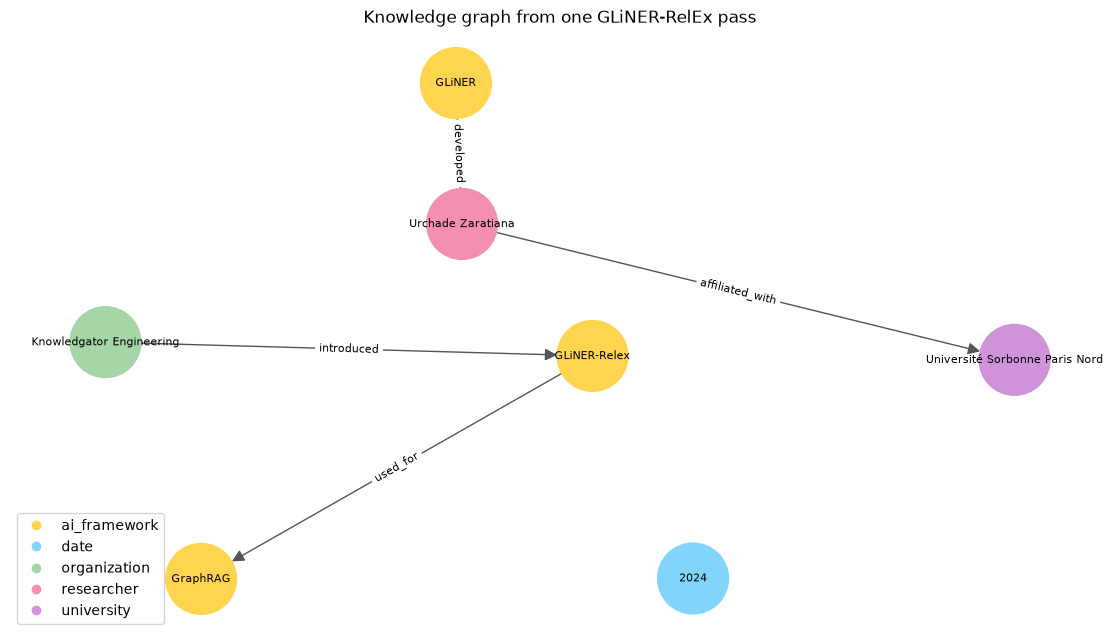

In [12]:
import networkx as nx, matplotlib.pyplot as plt
G = nx.DiGraph()
for e in ents3: G.add_node(e["text"], label=e["label"])
for r in rels3: G.add_edge(r["head"]["text"], r["tail"]["text"], rel=r["relation"])
types = sorted({d["label"] for _, d in G.nodes(data=True)})
cmap = {l: PALETTE[i % len(PALETTE)] for i, l in enumerate(types)}
pos = nx.spring_layout(G, seed=7, k=1.6)
plt.figure(figsize=(11, 6))
nx.draw(G, pos, with_labels=True, node_color=[cmap[G.nodes[n]["label"]] for n in G],
        node_size=2600, font_size=8, arrowsize=18, edge_color="#555")
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "rel"), font_size=8)
plt.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=cmap[l], label=l) for l in types], loc="lower left")
plt.title("Knowledge graph from one GLiNER-RelEx pass"); plt.show()

---
## Takeaways
1. **Extract:** one small model, any label schema, exact character offsets.
2. **Protect:** the same mechanism fine-tuned for PII runs fully on-device. Test your labels and add rules for guarantees.
3. **Connect:** RelEx extends GLiNER to relations, so entities and edges come from a single pass, with provenance.

All three run on CPU, with inference in tens to hundreds of milliseconds on this machine.